# Лабораторная 6 — вариант 23
Исследование guidance_scale у SD-Turbo для визуала экологического лектория.

Режим A — 0.0, режим B — 3.0. Серия seed 101–105. Гипотеза и допуски зафиксированы в `reports/hypothesis.md` до запуска. Для работы используется отдельная среда Colab с GPU T4.


## 1. Исходная среда

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path('/content/LR06')
ROOT.mkdir(parents=True, exist_ok=True)
parts = [sys.version]
for cmd in (['nvidia-smi'], [sys.executable, '-m', 'pip', 'list']):
    result = subprocess.run(cmd, capture_output=True, text=True)
    parts.append(result.stdout + result.stderr)
    if result.returncode:
        raise RuntimeError(f'Команда не выполнена: {cmd}')
text = '\n'.join(parts)
(ROOT / 'environment_before.txt').write_text(text, encoding='utf-8')
print(text)


3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Thu Oct 15 16:27:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

## 2. Зависимости
Версии Diffusers и Transformers совпадают с выполненным запуском ЛР 5. Установка выполняется до импорта библиотек модели. Фактическая среда сохраняется при запуске.

In [2]:
%pip install -q diffusers==0.40.0 transformers==5.18.0 accelerate safetensors Pillow scipy


## 3. Файлы эксперимента
Последовательно загружаются четыре файла из папки `Лабораторная6`. Для каждого открывается отдельное окно выбора; имена файлов сохраняются.

In [3]:
from google.colab import files
import hashlib

paths = ['lab05_lib.py', 'lab06_lib.py', 'tools/run_lab06.py', 'reports/hypothesis.md']
for relative in paths:
    destination = ROOT / relative
    print('Файл для загрузки:', relative)
    uploaded = files.upload()
    if set(uploaded) != {destination.name}:
        raise ValueError(f'Ожидался один файл {destination.name}')
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(uploaded[destination.name])
    print('Сохранён:', destination)
    print('SHA-256:', hashlib.sha256(destination.read_bytes()).hexdigest())


Файл для загрузки: lab05_lib.py


Saving lab05_lib.py to lab05_lib.py
Сохранён: /content/LR06/lab05_lib.py
SHA-256: 4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a
Файл для загрузки: lab06_lib.py


Saving lab06_lib.py to lab06_lib.py
Сохранён: /content/LR06/lab06_lib.py
SHA-256: c6d8473cf5a3000f4c27fbdef57916c2fbce347db272928d5c4729472f748bd8
Файл для загрузки: tools/run_lab06.py


Saving run_lab06.py to run_lab06.py
Сохранён: /content/LR06/tools/run_lab06.py
SHA-256: dada0fa00854a182fa2b8df005447ad57bf69a1c25da27ef6d6c025fd3eb834c
Файл для загрузки: reports/hypothesis.md


Saving hypothesis.md to hypothesis.md
Сохранён: /content/LR06/reports/hypothesis.md
SHA-256: d4323d63f4912afade78140bf8418615ae1af6ca11ef5b3904711c20fc969857


## 4. Гипотеза до запуска

In [4]:
from IPython.display import display, Markdown
display(Markdown((ROOT / 'reports/hypothesis.md').read_text(encoding='utf-8')))


# Гипотеза и допуски — вариант 23

Дата подготовки — 15.10.2026. Запись составлена до запуска эксперимента.

Исследуется визуал экологического лектория: стилизованный полог леса сверху, многослойные зелёные формы и мягкий утренний свет. Вариант 23 соответствует брифу 4 и фактору 5. Меняется только guidance_scale: в режиме A значение 0.0, в режиме B — 3.0.

Используется SD-Turbo, ревизия b261bac6fd2cf515557d5d0707481eafa0485ec2. В обоих режимах сохраняются английский запрос BRIEFS[3], размер 512×512, один шаг, float16 на GPU и свежий CPU-генератор для каждого вызова. Серия состоит из seed 101–105; каждый seed используется в обоих режимах. CLIP ViT-B/32 закреплён на ревизии 3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268. Сходство считается с исходным английским брифом.

Предполагается, что включение CFG при guidance=3.0 увеличит время генерации и изменит контраст и выраженность границ. Ожидается рост контраста и энергии границ, но он может сопровождаться грубыми переходами и потерей мягкой глубины зелёных слоёв. Устойчивого улучшения сходства CLIP не ожидается: для SD-Turbo рекомендован guidance=0.0. Это предположения, которые будут проверены по изображениям и измерениям.

Практические допуски выбраны по образцу задания.

| Метрика | Допуск для разности средних B−A | Классификация |
|---|---|---|
| CLIP, cosine × 100 | ±1.0 | Выше +1 — улучшение соответствия брифу; ниже −1 — ухудшение; внутри — нейтрально |
| Энергия границ | ±10% среднего A | Рост более 10% — условное улучшение выраженности границ; падение более 10% — ухудшение; внутри — нейтрально |
| Контраст | ±10% среднего A | Рост более 10% — условное улучшение контраста; падение более 10% — ухудшение; внутри — нейтрально |
| Время генерации | ±20% среднего A | Сокращение более 20% — улучшение; рост более 20% — ухудшение; внутри — нейтрально |

Равенство границе допуска относится к нейтральному изменению. Один пункт CLIP выбран как заметное изменение численной близости к брифу. Допуск 10% выделяет выраженный сдвиг визуальных метрик, а 20% для времени учитывает колебания нагрузки Colab. Эти пороги служат учебными ориентирами. Рост контраста и энергии границ оценивается вместе с изображениями: шум, пересветы и резкие переходы также увеличивают эти показатели.

По каждой метрике вычисляются среднее A, выборочное стандартное отклонение s по пяти значениям A, среднее B, Δ=B−A и |Δ|/s. Критерий |Δ|>2s рассматривается отдельно от практического допуска. Это учебный критерий выхода эффекта за разброс seed, без расчёта p-value. При s=0 отношение не определено для Δ=0 и бесконечно для ненулевой разности.

После основной классификации дополнительно проверяется её чувствительность к удвоению допусков. Основной вывод сохраняет исходные пороги.

Намеренная ошибка проверяется на seed 101: ожидание, что guidance=1.0 включает CFG. Предполагается совпадение изображений при guidance 0.0 и 1.0 и статус CFG=False. При guidance=3.0 ожидается CFG=True. Сохраняются изображения, SHA-256, равенство пикселей и PSNR. Дополнительно эта проверка повторяется для брифа 1 из демонстрационного примера.

Для сопоставления с методическими указаниями отдельно выполняется демонстрационный вариант 1, в котором меняется число шагов с 1 до 4. Его результаты не входят в расчёты варианта 23. После запуска визуально оцениваются глубина зелёных слоёв, светотеневые переходы и возможные артефакты. Изображения представляют художественную стилизацию леса.


## 5. Эксперимент
Сначала выполняется вариант 23, затем контроль guidance=1 и демонстрационный вариант 1. Скрипт сохраняет все изображения, исходные измерения, итоговые таблицы и паспорт. Время загрузки моделей записывается отдельно от времени генерации.

In [5]:
import importlib.util
spec = importlib.util.spec_from_file_location('run_lab06', ROOT / 'tools/run_lab06.py')
experiment = importlib.util.module_from_spec(spec)
spec.loader.exec_module(experiment)
result_dir = experiment.run()
print('Результаты:', result_dir)


[transformers] `Siglip2ImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `Siglip2ImageProcessor` instead.


Variant 23; started: 2026-10-15T16:29:54
Output: /content/LR06/artifacts/v23_20261015_162954_090155
{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "gpu": "Tesla T4",
  "cuda": "13.0",
  "packages": {
    "torch": "2.11.0+cu130",
    "torchvision": "0.26.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.18.0",
    "numpy": "2.1.3",
    "scipy": "1.16.3",
    "Pillow": "11.3.0",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
    "huggingface-hub": "1.33.0"
  },
  "deterministic_algorithms": false,
  "cudnn_benchmark": false,
  "tf32": false
}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Settings A/B: ({'prompt': 'visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people', 'steps': 1, 'guidance': 0.0, 'size': 512}, {'prompt': 'visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people', 'steps': 1, 'guidance': 3.0, 'size': 512})
variant=23 {'seed': 101, 'condition': 'A', 'clip': 34.61616039276123, 'edge': 0.04027313519880424, 'contrast': 0.1294336796588522, 'seconds': 0.277123620999987, 'cfg_active': False, 'image': 'A/seed_101.png', 'sha256': 'b8909a66262978ce4004e54c55a29af52eefc16a517dd4494e32394d49b5b32f'}
variant=23 {'seed': 101, 'condition': 'B', 'clip': 29.196542501449585, 'edge': 0.07398840645020349, 'contrast': 0.2564414715390134, 'seconds': 0.34057915799996863, 'cfg_active': True, 'image': 'B/seed_101.png', 'sha256': '028a81fffcc87aaafac8cb4cc470ef704e0cafeb8dfeb7eae43022519e61bf2d'}
variant=23 {'seed

## 6. Таблицы и изображения
В сравнительном листе слева расположен режим A, справа — B. Дополнительно показаны все пять пар для оценки устойчивости визуальных изменений.

summary.csv


,metric,A,s,B,delta,ratio,statistical,change_percent,practical_limit,practical
0,clip,33.107296,0.933354,31.048233,-2.059063,2.206089,True,-6.219362,1.000000,deterioration
1,edge,0.039345,0.001865,0.073990,0.034645,18.579382,True,88.056222,0.003934,improvement
2,contrast,0.122413,0.006253,0.254628,0.132215,21.142729,True,108.007596,0.012241,improvement
3,seconds,0.282008,0.005976,0.341235,0.059227,9.910422,True,21.001811,0.056402,deterioration


measurements.csv


,seed,condition,clip,edge,contrast,seconds,cfg_active,image,sha256
0,101,A,34.616160,0.040273,0.129434,0.277124,False,A/seed_101.png,b8909a66262978ce4004e54c55a29af52eefc16a517dd4...
1,101,B,29.196543,0.073988,0.256441,0.340579,True,B/seed_101.png,028a81fffcc87aaafac8cb4cc470ef704e0cafeb8dfeb7...
2,102,A,33.039564,0.039512,0.119358,0.279480,False,A/seed_102.png,949750bfd52f4d6adf27abba1cde4984085bc0be291b28...
3,102,B,33.368236,0.075711,0.255150,0.339254,True,B/seed_102.png,fd73ad5ae6e654c388f19f563c899a2639b2f501445154...
4,103,A,32.051310,0.041035,0.122871,0.277317,False,A/seed_103.png,c2a6cac8376e376270b6b362a2a247d7e0b01b794c2770...
5,103,B,30.398425,0.076335,0.245726,0.339452,True,B/seed_103.png,661e3ab0f0d33ab35798db7f8ae8a75c1c80c27b5d70a5...
6,104,A,32.998580,0.039723,0.126826,0.285116,False,A/seed_104.png,643394ca408f606250b7a264d9650a53a8020fc2ae5390...
7,104,B,30.948710,0.073933,0.262328,0.339479,True,B/seed_104.png,f168832e9fa9a650ba56b4f21aacfea8d91c907bbee450...
8,105,A,32.830864,0.036180,0.113575,0.291005,False,A/seed_105.png,83f325feeaaa12ba8e778fff20905cfb9f78e7dc02c7c2...
9,105,B,31.329250,0.069983,0.253494,0.347413,True,B/seed_105.png,1732e7da6825ff165429dc607dfe54adfe3a9259f9c49c...


Чувствительность к удвоению допусков


,metric,A,s,B,delta,ratio,statistical,change_percent,practical_limit,practical
0,clip,33.107296,0.933354,31.048233,-2.059063,2.206089,True,-6.219362,2.000000,deterioration
1,edge,0.039345,0.001865,0.073990,0.034645,18.579382,True,88.056222,0.007869,improvement
2,contrast,0.122413,0.006253,0.254628,0.132215,21.142729,True,108.007596,0.024483,improvement
3,seconds,0.282008,0.005976,0.341235,0.059227,9.910422,True,21.001811,0.112803,neutral


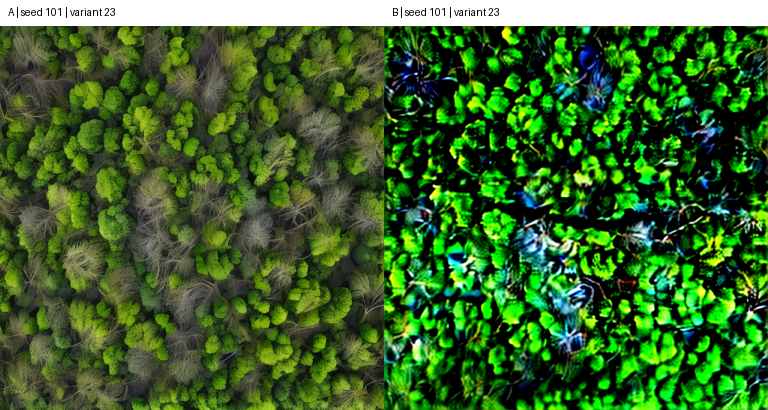

seed 101 | A: guidance=0.0 | B: guidance=3.0


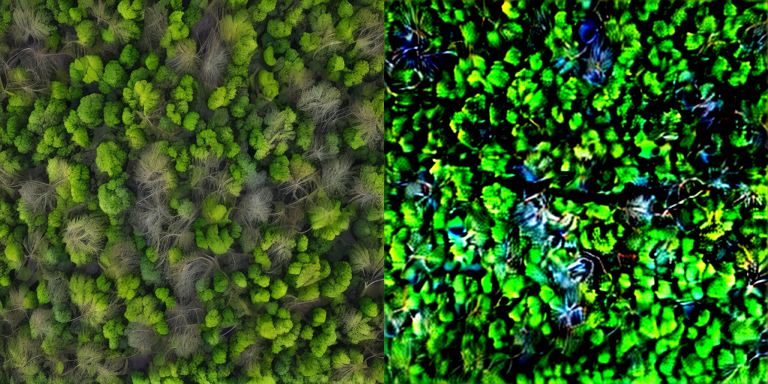

seed 102 | A: guidance=0.0 | B: guidance=3.0


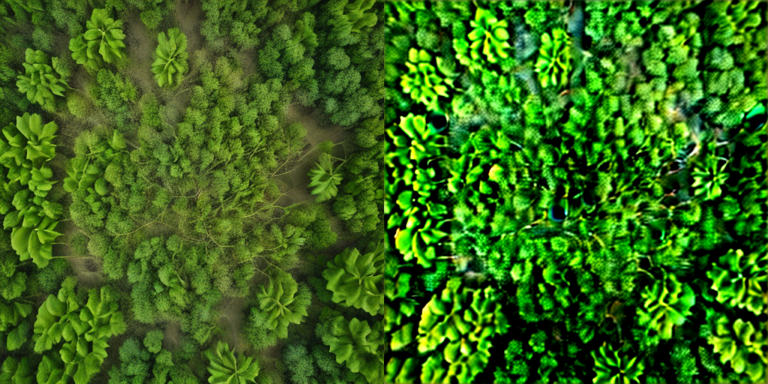

seed 103 | A: guidance=0.0 | B: guidance=3.0


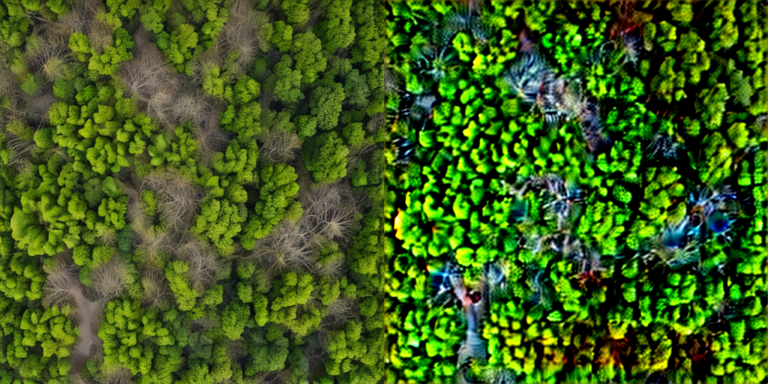

seed 104 | A: guidance=0.0 | B: guidance=3.0


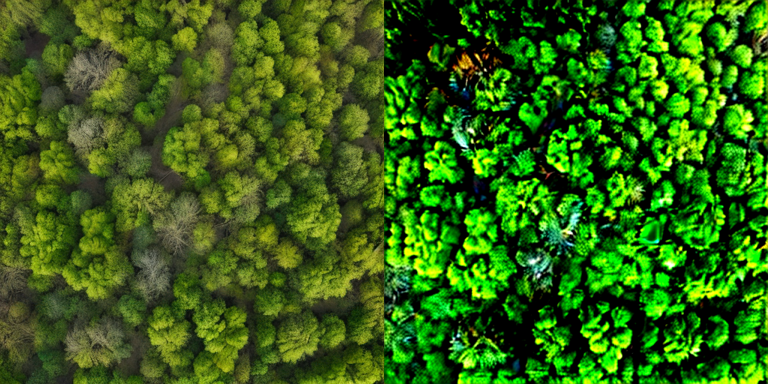

seed 105 | A: guidance=0.0 | B: guidance=3.0


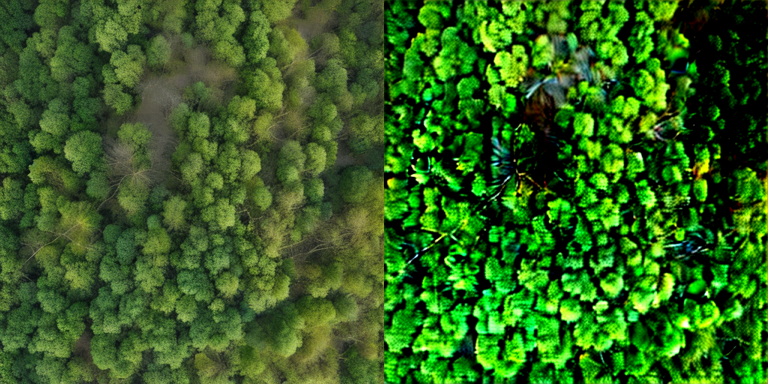

Проверка guidance=1
{
  "seed": 101,
  "brief": 4,
  "cfg_active": {
    "0": false,
    "1": false,
    "3": true
  },
  "sha256": {
    "0": "b8909a66262978ce4004e54c55a29af52eefc16a517dd4494e32394d49b5b32f",
    "1": "b8909a66262978ce4004e54c55a29af52eefc16a517dd4494e32394d49b5b32f",
    "3": "028a81fffcc87aaafac8cb4cc470ef704e0cafeb8dfeb7eae43022519e61bf2d"
  },
  "equal_0_1": true,
  "maxdiff_0_1": 0,
  "psnr_0_1": null,
  "psnr_0_3": 12.490741739416029
}
Демонстрационный вариант 1


,metric,A,s,B,delta,ratio,statistical,change_percent,practical_limit,practical
0,clip,30.797867,1.430902,30.292003,-0.505863,0.353528,False,-1.642528,1.000000,neutral
1,edge,0.045661,0.006960,0.091976,0.046315,6.654040,True,101.433387,0.004566,improvement
2,contrast,0.192287,0.022494,0.277862,0.085575,3.804418,True,44.503734,0.019229,improvement
3,seconds,0.281219,0.002351,0.524383,0.243164,103.430259,True,86.467664,0.056244,deterioration


In [6]:
import json
import pandas as pd
from PIL import Image
from IPython.display import display

for filename in ('summary.csv', 'measurements.csv'):
    print(filename)
    display(pd.read_csv(result_dir / filename))
print('Чувствительность к удвоению допусков')
display(pd.DataFrame(json.loads((result_dir / 'sensitivity_double_tolerance.json').read_text())))
display(Image.open(result_dir / 'comparison.png'))
for seed in range(101, 106):
    sheet = Image.new('RGB', (768,384))
    for i, condition in enumerate(('A','B')):
        with Image.open(result_dir / condition / f'seed_{seed}.png') as img:
            sheet.paste(img.resize((384,384)), (384*i,0))
    print('seed', seed, '| A: guidance=0.0 | B: guidance=3.0')
    display(sheet)
print('Проверка guidance=1')
print((result_dir / 'guidance_control/checks.json').read_text())
print('Демонстрационный вариант 1')
display(pd.read_csv(result_dir / 'demo_variant1/summary.csv'))


## 7. Архив результатов
Архив содержит папку запуска. Выполненный блокнот сохраняется отдельно в формате IPYNB с выводом ячеек.

In [7]:
import shutil
from google.colab import files
archive = shutil.make_archive(str(result_dir), 'zip', root_dir=result_dir.parent, base_dir=result_dir.name)
print(archive)
files.download(archive)


/content/LR06/artifacts/v23_20261015_162954_090155.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>